# Retail Sales Analytics — Exploratory Notebook

This notebook walks through the full analysis pipeline interactively:
data loading, cleaning, EDA, correlation analysis, and model building.

For the production pipeline, see `run_pipeline.py` and the `src/` package.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

from src.preprocessing import load_data, run_pipeline
from src.analysis import (
    summary_statistics, correlation_matrix, category_performance,
    regional_performance, monthly_trend, top_products
)

## 1. Load Raw Data

In [2]:
raw_df = load_data()
print(raw_df.shape)
raw_df.head()

2026-08-03 11:56:30 | src.preprocessing | INFO | Loading raw data from /home/claude/Project/data/raw/sales_data.csv


2026-08-03 11:56:30 | src.preprocessing | INFO | Loaded 2015 rows and 13 columns


(2015, 13)


,OrderID,Date,Category,Product,Region,UnitPrice,Quantity,DiscountPct,Sales,Cost,Profit,CustomerAge,SatisfactionScore
0,ORD100954,2022-01-02,Toys,Action Figure,South,38.31,9,0,344.79,246.83,97.96,31.0,4.0
1,ORD101373,2022-01-03,Clothing,Sneakers,West,49.42,4,0,197.68,122.83,74.85,NaN,5.0
2,ORD100662,2022-01-04,Beauty,Lipstick,Central,33.03,2,20,52.85,49.36,3.49,44.0,3.0
3,ORD100524,2022-01-04,Beauty,Sunscreen,NaN,26.75,9,0,240.75,146.43,94.32,18.0,5.0
4,ORD101344,2022-01-04,Beauty,Lipstick,Central,19.97,6,0,119.82,86.71,33.11,51.0,4.0


## 2. Data Quality Check (before cleaning)

In [3]:
print('Missing values:\n', raw_df.isnull().sum())
print('\nDuplicate rows:', raw_df.duplicated().sum())

Missing values:
 OrderID               0
Date                  0
Category              0
Product               0
Region               29
UnitPrice             0
Quantity              0
DiscountPct           0
Sales                 0
Cost                  0
Profit                0
CustomerAge          63
SatisfactionScore    48
dtype: int64

Duplicate rows: 15


## 3. Run Full Cleaning & Feature Engineering Pipeline

In [4]:
df = run_pipeline(save=True)
print(df.shape)
df.head()

2026-08-03 11:56:30 | src.preprocessing | INFO | Loading raw data from /home/claude/Project/data/raw/sales_data.csv


2026-08-03 11:56:30 | src.preprocessing | INFO | Loaded 2015 rows and 13 columns


2026-08-03 11:56:30 | src.preprocessing | INFO | Removed 15 duplicate rows


2026-08-03 11:56:30 | src.preprocessing | INFO | Imputed 140 missing values


2026-08-03 11:56:30 | src.preprocessing | INFO | Capped 915 outlier values across ['Sales', 'Quantity', 'Profit', 'UnitPrice']


2026-08-03 11:56:30 | src.preprocessing | INFO | Feature engineering complete: Year, Month, Quarter, ProfitMargin, AvgOrderValue, HighValueOrder added


2026-08-03 11:56:30 | src.preprocessing | INFO | Saved cleaned dataset to /home/claude/Project/data/processed/sales_data_clean.csv


(2000, 21)


,OrderID,Date,Category,Product,Region,UnitPrice,Quantity,DiscountPct,Sales,Cost,...,CustomerAge,SatisfactionScore,Year,Month,MonthName,Quarter,DayOfWeek,ProfitMargin,AvgOrderValue,HighValueOrder
0,ORD100954,2022-01-02,Toys,Action Figure,South,38.31,9,0,344.79,246.83,...,31.0,4.0,2022,1,January,1,Sunday,28.411497,38.310,1
1,ORD101373,2022-01-03,Clothing,Sneakers,West,49.42,4,0,197.68,122.83,...,34.0,5.0,2022,1,January,1,Monday,37.864225,49.420,0
2,ORD100662,2022-01-04,Beauty,Lipstick,Central,33.03,2,20,52.85,49.36,...,44.0,3.0,2022,1,January,1,Tuesday,6.603595,26.425,0
3,ORD100524,2022-01-04,Beauty,Sunscreen,West,26.75,9,0,240.75,146.43,...,18.0,5.0,2022,1,January,1,Tuesday,39.177570,26.750,0
4,ORD101344,2022-01-04,Beauty,Lipstick,Central,19.97,6,0,119.82,86.71,...,51.0,4.0,2022,1,January,1,Tuesday,27.633116,19.970,0


## 4. Statistical Summary

In [5]:
summary_statistics(df)

2026-08-03 11:56:30 | src.analysis | INFO | Saved summary statistics to /home/claude/Project/outputs/summary_statistics.csv


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
UnitPrice,2000.0,67.80,44.31,10.21,35.03,50.18,82.84,154.54,1.10,-0.21
Quantity,2000.0,5.04,1.93,1.00,4.00,5.00,6.00,9.00,0.19,-0.53
DiscountPct,2000.0,3.32,5.54,0.00,0.00,0.00,5.00,20.00,1.62,1.58
Sales,2000.0,338.71,257.86,23.49,151.59,243.60,436.20,863.10,1.09,-0.15
Cost,2000.0,279.70,316.42,14.06,98.35,163.75,294.52,2258.28,2.45,6.41
Profit,2000.0,109.35,85.42,2.88,46.99,78.74,142.27,285.17,1.07,-0.16
CustomerAge,2000.0,34.96,11.16,18.00,27.00,34.00,42.00,74.00,0.44,-0.16
SatisfactionScore,2000.0,3.53,0.90,1.00,3.00,4.00,4.00,5.00,-0.15,-0.47
Year,2000.0,2023.00,0.82,2022.00,2022.00,2023.00,2024.00,2024.00,0.00,-1.52
Month,2000.0,6.38,3.46,1.00,3.00,6.00,9.00,12.00,0.04,-1.21


## 5. Category & Regional Performance

In [6]:
category_performance(df)

2026-08-03 11:56:30 | src.analysis | INFO | Computed category-level performance summary


,TotalSales,TotalProfit,AvgOrderValue,OrderCount,AvgSatisfaction
Category,,,,,
Electronics,283316.46,91480.18,793.60,357,3.57
Home & Kitchen,121492.12,39507.74,386.92,314,3.62
Sports,92189.57,29957.87,291.74,316,3.53
Clothing,69312.04,22257.57,206.90,335,3.53
Toys,61748.54,19554.96,183.78,336,3.42
Beauty,49364.28,15937.06,144.34,342,3.50


In [7]:
regional_performance(df)

2026-08-03 11:56:30 | src.analysis | INFO | Computed regional performance summary


,TotalSales,TotalProfit,OrderCount
Region,,,
West,153344.62,49276.38,447
South,135218.60,44101.41,398
East,135028.18,44082.97,382
Central,129696.43,41738.47,389
North,124135.17,39496.15,384


## 6. Correlation Analysis

2026-08-03 11:56:30 | src.analysis | INFO | Computed correlation matrix


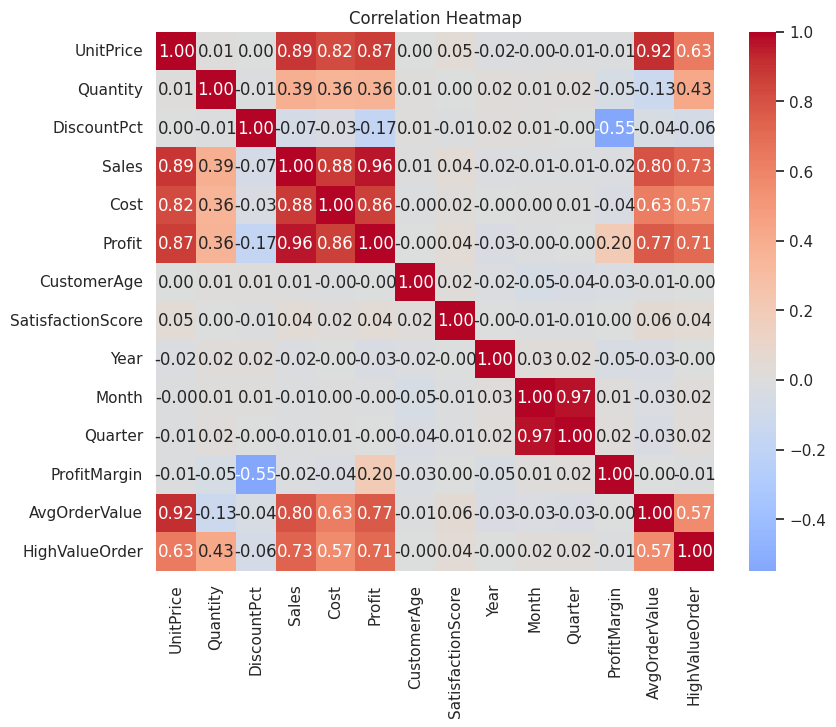

In [8]:
corr = correlation_matrix(df)
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

## 7. Trend Analysis

2026-08-03 11:56:30 | src.analysis | INFO | Computed monthly sales/profit trend


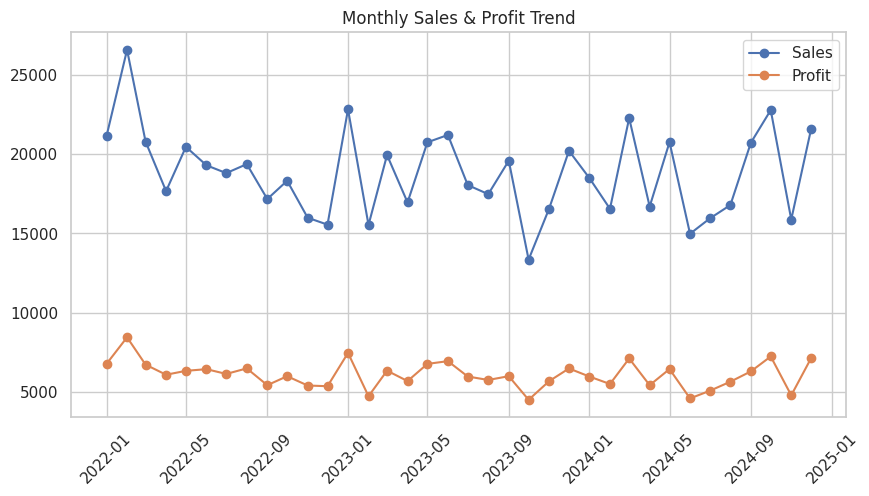

In [9]:
trend = monthly_trend(df)
plt.figure(figsize=(10,5))
plt.plot(trend['Date'], trend['TotalSales'], marker='o', label='Sales')
plt.plot(trend['Date'], trend['TotalProfit'], marker='o', label='Profit')
plt.legend(); plt.title('Monthly Sales & Profit Trend'); plt.xticks(rotation=45)
plt.show()

## 8. Top Products

In [10]:
top_products(df, n=10)

,Product,Sales
0,Smartwatch,66714.47250
1,Headphones,58262.59125
2,Smartphone,54551.18500
3,Tablet,53272.78875
4,Laptop,50515.42125
5,Air Fryer,27505.28875
6,Blender,27331.63000
7,Vacuum Cleaner,24773.70000
8,Cookware Set,22636.03750
9,Football,22126.94875


## 9. Model Building

We train two models:
- A **regression** model to predict order `Sales`
- A **classification** model to predict whether an order is `HighValueOrder`

In [11]:
from src.model import train_regression_model, train_classification_model, save_prediction_results

reg_result = train_regression_model(df)
clf_result = train_classification_model(df)

print('Regression metrics:', reg_result['metrics'])
print('Classification metrics:', clf_result['metrics'])

2026-08-03 11:56:31 | src.model | INFO | Regression model metrics: {'MAE': 18.73, 'RMSE': 44.09, 'R2': 0.971}


2026-08-03 11:56:32 | src.model | INFO | Classification model metrics: {'Accuracy': 0.98, 'Precision': 0.98, 'Recall': 0.98, 'F1': 0.98, 'ROC_AUC': 0.998}


Regression metrics: {'MAE': 18.73, 'RMSE': 44.09, 'R2': 0.971}
Classification metrics: {'Accuracy': 0.98, 'Precision': 0.98, 'Recall': 0.98, 'F1': 0.98, 'ROC_AUC': 0.998}


## 10. Save Prediction Results

In [12]:
results = save_prediction_results(df, reg_result, clf_result)
results.head()

2026-08-03 11:56:32 | src.model | INFO | Saved prediction results to /home/claude/Project/outputs/prediction_results.csv


,UnitPrice,Quantity,DiscountPct,CustomerAge,SatisfactionScore,Month,Quarter,Category_enc,Region_enc,ActualSales,PredictedSales,SalesPredictionError,ActualHighValue,PredictedHighValue,HighValueProbability
0,64.05,8,0,26.0,3.0,10,4,4,2,512.40,502.377416,10.022584,0,0,0.012
1,57.77,6,0,67.0,3.0,6,2,4,3,346.62,342.645651,3.974349,0,0,0.055
2,26.07,3,0,38.0,4.0,1,1,5,4,78.21,84.508450,-6.298450,1,1,0.945
3,34.96,2,0,18.0,3.0,5,2,5,4,69.92,67.898754,2.021246,0,1,0.666
4,24.56,5,0,31.0,4.0,12,4,0,2,122.80,121.638533,1.161467,0,0,0.079


## 11. Conclusion

Electronics leads in total sales and profit, the West region outperforms
other regions, and the Random Forest models achieve strong predictive
performance (see metrics above). See `reports/report.md` for the full
written analysis, business insights, and recommendations.